<a href="https://colab.research.google.com/github/251ce010-ctrl/Genetic-Disorder-Subclass-Screening-System/blob/main/Genetic_Disorder_Subclass_Screening_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Step 1 – Import Libraries**

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

**Step 2 – Upload Training Dataset**

In [ ]:
uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])

print(df.head())
print(df.shape)
print(df.columns)

Saving train_genetic_disorders.csv to train_genetic_disorders.csv
  Patient Id  Patient Age Genes in mother's side Inherited from father  \
0  PID0x6418          2.0                    Yes                    No   
1  PID0x25d5          4.0                    Yes                   Yes   
2  PID0x4a82          6.0                    Yes                    No   
3  PID0x4ac8         12.0                    Yes                    No   
4  PID0x1bf7         11.0                    Yes                    No   

  Maternal gene Paternal gene  Blood cell count (mcL) Patient First Name  \
0           Yes            No                4.760603            Richard   
1            No            No                4.910669               Mike   
2            No            No                4.893297           Kimberly   
3           Yes            No                4.705280            Jeffery   
4           NaN           Yes                4.720703            Johanna   

  Family Name Father's name  ...

**Step 3 – Dataset Information**

In [ ]:
df.info()

print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

print(df['Disorder Subclass'].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22083 entries, 0 to 22082
Data columns (total 45 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Patient Id                                        21011 non-null  object 
 1   Patient Age                                       19643 non-null  float64
 2   Genes in mother's side                            21011 non-null  object 
 3   Inherited from father                             20724 non-null  object 
 4   Maternal gene                                     18317 non-null  object 
 5   Paternal gene                                     21011 non-null  object 
 6   Blood cell count (mcL)                            21011 non-null  float64
 7   Patient First Name                                21011 non-null  object 
 8   Family Name                                       11771 non-null  object 
 9   Father's name    

**Step 4 – Remove Missing Target and Duplicates**

In [ ]:
df = df.dropna(subset=['Disorder Subclass'])

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Dataset Shape:", df.shape)

Dataset Shape: (18943, 45)


**Step 5 – Remove Unwanted Columns**

In [ ]:
drop_columns = [
    'Patient Id',
    'Patient First Name',
    'Family Name',
    "Father's name",
    'Institute Name',
    'Location of Institute',
    'Genetic Disorder'
]

df = df.drop(columns=drop_columns)

print("Remaining Columns:", df.shape[1])

print(df.head())

Remaining Columns: 38
   Patient Age Genes in mother's side Inherited from father Maternal gene  \
0          2.0                    Yes                    No           Yes   
1          4.0                    Yes                   Yes            No   
2          6.0                    Yes                    No            No   
3         12.0                    Yes                    No           Yes   
4         11.0                    Yes                    No           NaN   

  Paternal gene  Blood cell count (mcL)  Mother's age  Father's age    Status  \
0            No                4.760603           NaN           NaN     Alive   
1            No                4.910669           NaN          23.0  Deceased   
2            No                4.893297          41.0          22.0     Alive   
3            No                4.705280          21.0           NaN  Deceased   
4           Yes                4.720703          32.0           NaN     Alive   

  Respiratory Rate (breaths/

**Step 6 – Handle Missing Values**

In [ ]:
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_cols = df.select_dtypes(
    include=['object']
).columns

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if col != 'Disorder Subclass':
        df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

Patient Age                                         0
Genes in mother's side                              0
Inherited from father                               0
Maternal gene                                       0
Paternal gene                                       0
Blood cell count (mcL)                              0
Mother's age                                        0
Father's age                                        0
Status                                              0
Respiratory Rate (breaths/min)                      0
Heart Rate (rates/min                               0
Test 1                                              0
Test 2                                              0
Test 3                                              0
Test 4                                              0
Test 5                                              0
Parental consent                                    0
Follow-up                                           0
Gender                      

**Step 7 – Categorical Encoding**

In [ ]:
label_encoders = {}

for col in df.select_dtypes(include=['object']).columns:

    le = LabelEncoder()

    df[col] = le.fit_transform(df[col].astype(str))

    label_encoders[col] = le

print("Categorical Encoding Completed!")

print(df.head())

Categorical Encoding Completed!
   Patient Age  Genes in mother's side  Inherited from father  Maternal gene  \
0          2.0                       1                      0              1   
1          4.0                       1                      1              0   
2          6.0                       1                      0              0   
3         12.0                       1                      0              1   
4         11.0                       1                      0              1   

   Paternal gene  Blood cell count (mcL)  Mother's age  Father's age  Status  \
0              0                4.760603          35.0          42.0       0   
1              0                4.910669          35.0          23.0       1   
2              0                4.893297          41.0          22.0       0   
3              0                4.705280          21.0          42.0       1   
4              1                4.720703          32.0          42.0       0   

   Res

**Step 8 – Separate Features and Target**

In [ ]:
X = df.drop('Disorder Subclass', axis=1)

y = df['Disorder Subclass']

print(X.shape)
print(y.shape)

(18943, 37)
(18943,)


**Step 9 – Train Test Split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(15154, 37)
(3789, 37)


**Step 10 – Standardization**

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Standardization Completed!")

Standardization Completed!


**Step 11 – Feature Selection**

In [ ]:
selector = SelectKBest(
    score_func=f_classif,
    k=20
)

X_train_selected = selector.fit_transform(
    X_train_scaled, y_train
)

X_test_selected = selector.transform(
    X_test_scaled
)

print("Feature Selection Completed!")

Feature Selection Completed!


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [11 12 13 14 15 16] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


**Step 12 – Linear SVM**

In [ ]:
linear_model = SVC(kernel='linear')

linear_model.fit(X_train_selected, y_train)

linear_pred = linear_model.predict(X_test_selected)

**Step 13 – Polynomial SVM**

In [ ]:
poly_model = SVC(kernel='poly', degree=3)

poly_model.fit(X_train_selected, y_train)

poly_pred = poly_model.predict(X_test_selected)

**Step 14 – RBF SVM**

In [ ]:
rbf_model = SVC(kernel='rbf')

rbf_model.fit(X_train_selected, y_train)

rbf_pred = rbf_model.predict(X_test_selected)

print("All SVM Models Trained Successfully!")

All SVM Models Trained Successfully!


**Step 15 – Accuracy Comparison**

In [ ]:
linear_acc = accuracy_score(y_test, linear_pred)

poly_acc = accuracy_score(y_test, poly_pred)

rbf_acc = accuracy_score(y_test, rbf_pred)

print("Linear Accuracy:", linear_acc * 100)

print("Polynomial Accuracy:", poly_acc * 100)

print("RBF Accuracy:", rbf_acc * 100)

Linear Accuracy: 40.432831881763
Polynomial Accuracy: 37.820005278437584
RBF Accuracy: 40.195302190551594


**Step 16 – Classification Report**


In [ ]:
print("LINEAR SVM")
print(classification_report(y_test, linear_pred))

print("POLYNOMIAL SVM")
print(classification_report(y_test, poly_pred))

print("RBF SVM")
print(classification_report(y_test, rbf_pred))

LINEAR SVM
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        30
           1       0.00      0.00      0.00        18
           2       0.40      0.67      0.50       655
           3       0.00      0.00      0.00       349
           4       0.00      0.00      0.00       258
           5       0.00      0.00      0.00       121
           6       0.45      0.57      0.50       979
           7       0.38      0.38      0.38       841
           8       0.36      0.41      0.38       538

    accuracy                           0.40      3789
   macro avg       0.18      0.23      0.20      3789
weighted avg       0.32      0.40      0.35      3789

POLYNOMIAL SVM
              precision    recall  f1-score   support

           0       0.50      0.07      0.12        30
           1       0.00      0.00      0.00        18
           2       0.42      0.56      0.48       655
           3       0.36      0.22      0.27       34

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

**Step 17 – Confusion Matrix**

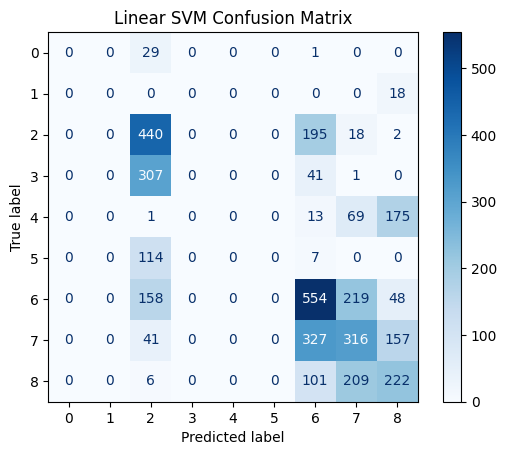

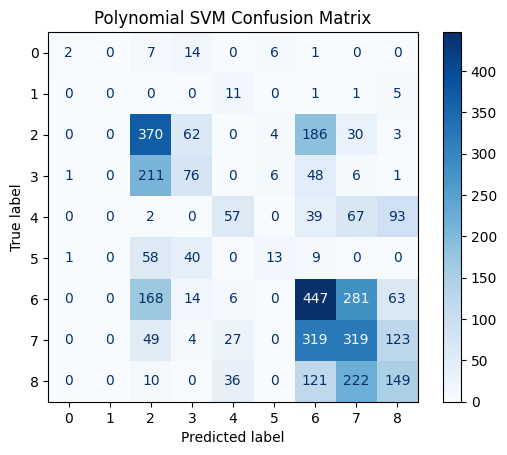

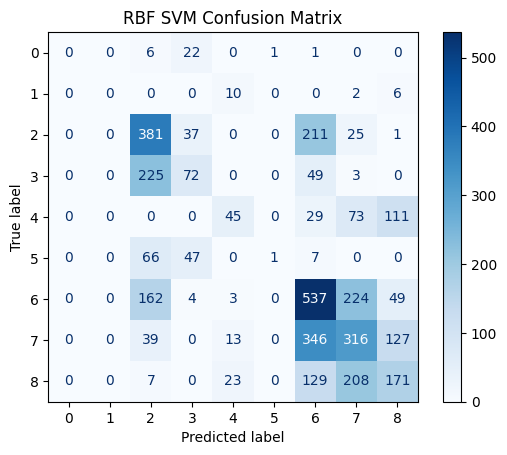

In [ ]:
models = {
    "Linear": linear_pred,
    "Polynomial": poly_pred,
    "RBF": rbf_pred
}

for name, pred in models.items():

    cm = confusion_matrix(y_test, pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm
    )

    disp.plot(cmap='Blues')

    plt.title(name + " SVM Confusion Matrix")

    plt.show()

**Step 18 – Kernel Comparison Graph**

       Kernel   Accuracy
0      Linear  40.432832
1  Polynomial  37.820005
2         RBF  40.195302


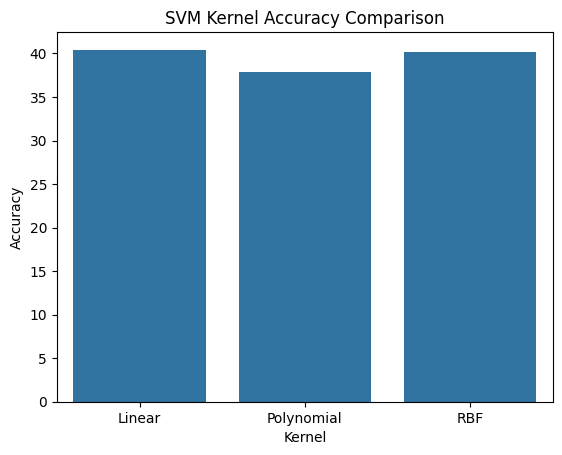

In [ ]:
results = pd.DataFrame({
    'Kernel': ['Linear', 'Polynomial', 'RBF'],
    'Accuracy': [
        linear_acc * 100,
        poly_acc * 100,
        rbf_acc * 100
    ]
})

print(results)

sns.barplot(
    data=results,
    x='Kernel',
    y='Accuracy'
)

plt.title("SVM Kernel Accuracy Comparison")

plt.show()

**Step 19 – Best Kernel Selection**

In [ ]:
best_kernel = results.loc[
    results['Accuracy'].idxmax(), 'Kernel'
]

print("Best SVM Kernel:", best_kernel)





Best SVM Kernel: Linear


In [ ]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

**Step 21 – Reload Original Training Dataset**

In [ ]:
train_raw = pd.read_csv(list(uploaded.keys())[0])

train_raw = train_raw.dropna(
    subset=['Disorder Subclass']
)

train_raw = train_raw.drop_duplicates()

print(train_raw.shape)

(18943, 45)


**Step 22 – Clean Invalid Values**

In [ ]:
train_raw = train_raw.replace([-99, '-99'], np.nan)

drop_cols = [
    'Patient Id',
    'Patient First Name',
    'Family Name',
    "Father's name",
    'Institute Name',
    'Location of Institute',
    'Genetic Disorder'
]

train_raw = train_raw.drop(
    columns=drop_cols,
    errors='ignore'
)

print(train_raw.shape)

(18943, 38)


**Step 23 – Separate X and y**

In [ ]:
X = train_raw.drop(
    'Disorder Subclass', axis=1
)

y = train_raw['Disorder Subclass']

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (15154, 37)
Validation: (3789, 37)


**Step 24 – Preprocessing Pipeline**

In [ ]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing Pipeline Created!")

Preprocessing Pipeline Created!


**Step 25 – Train Three SVM Kernels**

In [ ]:
kernels = ['linear', 'poly', 'rbf']

models = {}
results = []

for kernel in kernels:

    model = Pipeline([
        ('preprocessing', preprocessor),
        ('selection', SelectKBest(f_classif, k=20)),
        ('classifier', SVC(kernel=kernel, cache_size=1000))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)

    f1 = f1_score(
        y_val, predictions,
        average='macro',
        zero_division=0
    )

    models[kernel] = model

    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy * 100,
        'Macro F1': f1 * 100
    })

    print(kernel, "completed")

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 4  5  6  7  8 30] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


linear completed


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 4  5  6  7  8 30] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


poly completed


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 4  5  6  7  8 30] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


rbf completed


**Step 26 – Compare Performance**

In [ ]:
results_df = pd.DataFrame(results)

print(results_df)

best_kernel = results_df.loc[
    results_df['Macro F1'].idxmax(),
    'Kernel'
]

best_model = models[best_kernel]

print("Best Kernel:", best_kernel)

   Kernel   Accuracy   Macro F1
0  linear  39.799419  19.286360
1    poly  39.825812  26.788490
2     rbf  40.775930  25.499688
Best Kernel: poly


**Step 27 – Save Best Model**

In [ ]:
joblib.dump(best_model, 'genetic_disorder_model.pkl')

print("Best Model Saved Successfully!")

Best Model Saved Successfully!


**Step 28 – Test data prepare pannunga**

In [ ]:
from google.colab import files
import pandas as pd

test_uploaded = files.upload()

test_df = pd.read_csv(list(test_uploaded.keys())[0])

print("Test Dataset Loaded Successfully!")
print(test_df.shape)

Saving test_genetic_disorders.csv to test_genetic_disorders.csv
Test Dataset Loaded Successfully!
(9463, 43)


**Step 29 – Predict Disorder Subclass**

In [ ]:
# Remove unnecessary columns
test_features = test_df.drop(columns=drop_cols, errors='ignore')

# Handle invalid values
test_features = test_features.replace([-99, '-99'], np.nan)

# Match training columns and order
test_features = test_features.reindex(columns=X.columns)

# Predict using the best model
test_predictions = best_model.predict(test_features)

print("Prediction Completed Successfully!")
print(test_predictions[:10])

Prediction Completed Successfully!
['Cystic fibrosis' 'Mitochondrial myopathy' 'Tay-Sachs' 'Cystic fibrosis'
 'Cystic fibrosis' 'Diabetes' 'Cystic fibrosis' 'Diabetes' 'Tay-Sachs'
 'Leigh syndrome']


**Step 30 – Results CSV file create pannunga**

In [ ]:
prediction_df = pd.DataFrame({
    'Predicted Disorder Subclass': test_predictions
})

prediction_df.to_csv(
    'genetic_disorder_predictions.csv',
    index=False
)

print("Prediction file created successfully!")
prediction_df.head(10)

Prediction file created successfully!


,Predicted Disorder Subclass
0,Cystic fibrosis
1,Mitochondrial myopathy
2,Tay-Sachs
3,Cystic fibrosis
4,Cystic fibrosis
5,Diabetes
6,Cystic fibrosis
7,Diabetes
8,Tay-Sachs
9,Leigh syndrome


Step 1 – Save Model and Preprocessor

In [ ]:
import joblib

joblib.dump(best_model, "svm_model.pkl")

print("SVM Model Saved Successfully!")

SVM Model Saved Successfully!


**Step 2 – Download model**

In [ ]:
from google.colab import files

files.download("svm_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 3 – Flask API Development

Step 3.1 – Install Flask

In [ ]:
!pip install flask flask-cors

Step 3.2 – Create Flask API file

In [ ]:
%%writefile flask_api.py

from flask import Flask, request, jsonify
from flask_cors import CORS
import pandas as pd
import joblib

app = Flask(__name__)
CORS(app)

model = joblib.load("svm_model.pkl")

@app.route("/")
def home():
    return "Genetic Disorder Prediction API is Running!"

@app.route("/predict", methods=["POST"])
def predict():

    data = request.get_json()

    input_data = pd.DataFrame(data)

    prediction = model.predict(input_data)

    return jsonify({
        "Predicted Disorder Subclass": prediction.tolist()
    })

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

Writing flask_api.py


Step 3.3 – Download Flask API file

In [ ]:
from google.colab import files

files.download("flask_api.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(X.columns.tolist())

['Patient Age', "Genes in mother's side", 'Inherited from father', 'Maternal gene', 'Paternal gene', 'Blood cell count (mcL)', "Mother's age", "Father's age", 'Status', 'Respiratory Rate (breaths/min)', 'Heart Rate (rates/min', 'Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent', 'Follow-up', 'Gender', 'Birth asphyxia', 'Autopsy shows birth defect (if applicable)', 'Place of birth', 'Folic acid details (peri-conceptional)', 'H/O serious maternal illness', 'H/O radiation exposure (x-ray)', 'H/O substance abuse', 'Assisted conception IVF/ART', 'History of anomalies in previous pregnancies', 'No. of previous abortion', 'Birth defects', 'White Blood cell count (thousand per microliter)', 'Blood test result', 'Symptom 1', 'Symptom 2', 'Symptom 3', 'Symptom 4', 'Symptom 5']
